In [3]:
%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Análise e Comparação de Curvas de Juros: Cython vs B3
Neste notebook construímos as curvas Onshore (DIxPRE, SELICxPRE, TBFxPRE, TRxPRE) usando o Motor Cython. Extrairemos o Vértice 1 diretamente do Banco Central (SGS) e compararemos a curva final gerada com a curva oficial divulgada pela B3. Também validaremos o algoritmo de Suavização via Spline.

In [4]:
import os
import datetime
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from bcb import sgs

from bz_pricing.curves.builder import B3CurveBuilder
from bz_pricing.data.loaders import B3DataLoader
from bz_pricing.data.scrapers import B3Scraper
from bz_pricing.curves.manager import CurveManager

plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (14, 7)

In [5]:
from importlib import metadata
from pandas.tseries.offsets import BDay
# Configuração Base
base_date = datetime.date(2026, 9, 4)
data_dir = os.path.join("../dados/b3")
loader = B3DataLoader(data_dir)
builder = B3CurveBuilder()
manager = CurveManager(loader, builder)
scraper = B3Scraper(output_dir=data_dir)

# Baixa os 5 dias úteis anteriores caso não existam (necessário para TBF)
for i in range(1, 6):
    d = (pd.to_datetime(base_date) - BDay(i)).date()
    date_str = d.strftime('%Y%m%d')
    if not os.path.exists(os.path.join(data_dir, f'BVBG_SPRD_{date_str}.csv')):
        print(f'Baixando TBF histórico: {date_str}')
        scraper.download_bvbg_187_01(d)
    if not os.path.exists(os.path.join(data_dir, f'BVBG_IN_{date_str}.csv')):
        print(f'Baixando Cadastro de Instrumentos (IN) histórico: {date_str}')
        scraper.download_instruments(d)


## 1. Extração do Vértice 1 (BCB SGS)

In [6]:
# CDI (Série 12) e Selic Diária (Série 11) via Banco Central do Brasil
# sgs.get recebe start e end date como strings no formato '%Y-%m-%d'
start_str = (base_date - datetime.timedelta(days=7)).strftime('%Y-%m-%d')
end_str = base_date.strftime('%Y-%m-%d')
df_bcb = sgs.get({'CDI': 12, 'SELIC': 11}, start=start_str, end=end_str)
if not df_bcb.empty:
    cdi_d = float(df_bcb['CDI'].dropna().iloc[-1]) / 100.0
    selic_d = float(df_bcb['SELIC'].dropna().iloc[-1]) / 100.0
    v1_cdi = round(((1.0 + cdi_d) ** 252.0 - 1.0) * 10000.0) / 10000.0
    v1_selic = round(((1.0 + selic_d) ** 252.0 - 1.0) * 10000.0) / 10000.0
else:
    v1_cdi = 0.1390
    v1_selic = 0.1390

print(f'Vértice 1 CDI (SGS 12): {v1_cdi*100:.2f}% a.a.')
print(f'Vértice 1 SELIC (SGS 11): {v1_selic*100:.2f}% a.a.')

# Instanciando o CurveManager para orquestrar as curvas onshore e offshore
manager = CurveManager(loader=loader, builder=builder)


Vértice 1 CDI: 13.90%
Vértice 1 SELIC: 13.90%


## 2. Construindo a Curva PRE (DI x PRE) com e sem Suavização

In [7]:
# Extrai contratos DI1
df_di1 = loader.get_curve_instruments(base_date, asst="DI1")

# Constrói a curva Padrão B3 (Exponential Interpolator)
curve_pre_std = manager.get_curve("PRE", base_date)

# Constrói a curva com Suavização Spline
# Suavização pode ser feita no manager (hardcoded para teste) ou chamada manualmente
curve_pre_smooth = manager.builder.build_from_config(df_di1, "PRE", base_date, v1_rate=v1_cdi, smoothing=0.0001)

# Baixa a curva oficial da B3 para comparação
b3_pre_path = scraper.download_taxas_referenciais(data = base_date, produto = "PRE")

# Le os dados baixados
df_b3_pre = pd.read_csv(b3_pre_path, sep = ';')

Arquivo de taxas referenciais (PRE - 20260904) já existe em: ../dados/b3\taxas_PRE_20260904.csv. Use force=True para baixar novamente.


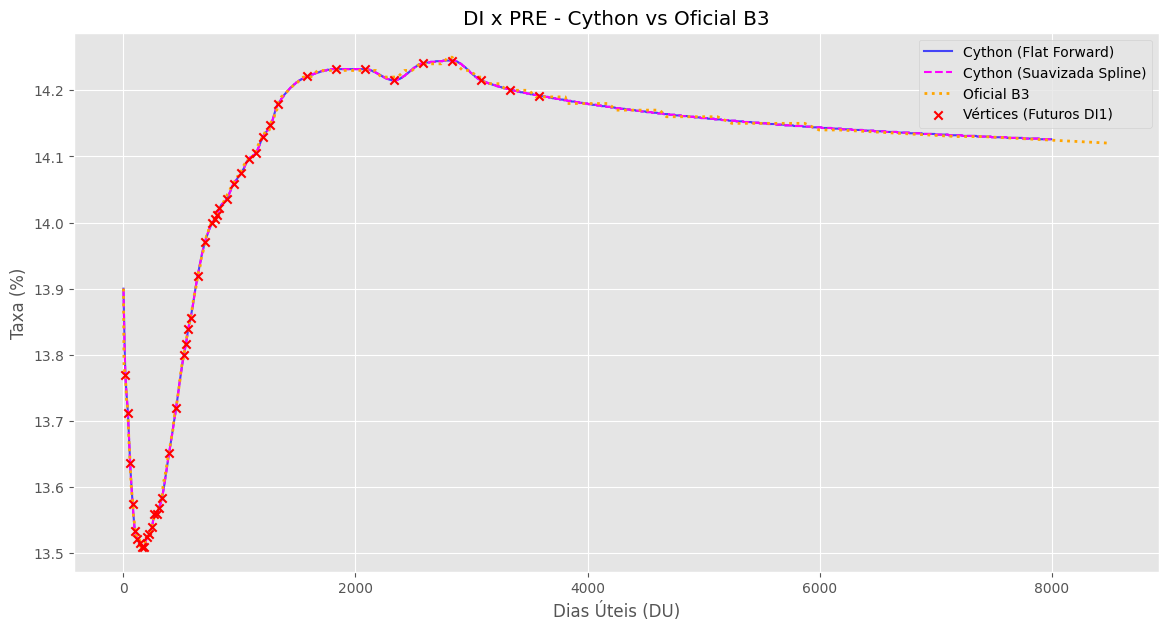

In [8]:
du_grid = np.arange(1, 8000, 5)
rates_std = [curve_pre_std.get_rate(float(du)) * 100 for du in du_grid]
rates_smooth = [curve_pre_smooth.get_rate(float(du)) * 100 for du in du_grid]

plt.plot(du_grid, rates_std, label='Cython (Flat Forward)', color='blue', alpha=0.7)
plt.plot(du_grid, rates_smooth, label='Cython (Suavizada Spline)', color='magenta', linestyle='--')

if df_b3_pre is not None and not df_b3_pre.empty:
    plt.plot(df_b3_pre['day252'], df_b3_pre['rate'], label='Oficial B3', color='orange', linewidth=2, linestyle=':')

# Pontos dos Contratos Futuros Originais
cal = builder.cal
df_di1['DU'] = [cal.bizdays(base_date, pd.to_datetime(d).date()) for d in df_di1['XprtnDt']]
df_di1_valid = df_di1[df_di1['DU'] > 0]
plt.scatter(df_di1_valid['DU'], df_di1_valid['AdjstdQtTax'], color='red', marker='x', label='Vértices (Futuros DI1)', zorder=5)

plt.title(f'DI x PRE - Cython vs Oficial B3')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (%)')
plt.legend()
plt.show()


## 3. Construindo a Curva SELIC x PRE

In [9]:
# OC1 Contracts (Liquidity Filter is now OFF in configs.py so we see the full curve)
df_oc1 = loader.get_curve_instruments(base_date, asst="OC1")

curve_selic = builder.build_from_config(df_oc1, "SELIC_PRE", base_date, v1_rate=v1_selic)

# Taxas Referenciais da B3
b3_selic_path = scraper.download_taxas_referenciais(data=base_date, produto="SLP")

# Le os dados baixados
df_b3_selic = pd.read_csv(b3_selic_path, sep = ';')

Arquivo de taxas referenciais (SLP - 20260904) já existe em: ../dados/b3\taxas_SLP_20260904.csv. Use force=True para baixar novamente.


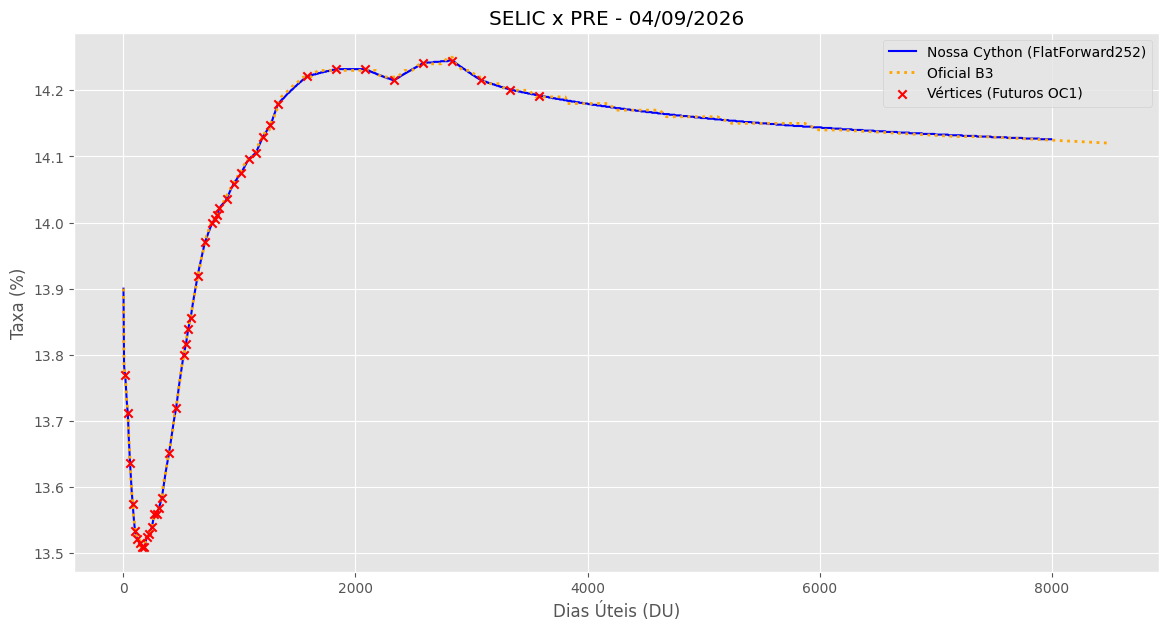

In [10]:
du_grid_selic = np.arange(1, 8000, 5)
rates_selic = [curve_selic.get_rate(float(du)) * 100 for du in du_grid_selic]

plt.plot(du_grid_selic, rates_selic, label='Nossa Cython (FlatForward252)', color='blue')

if df_b3_selic is not None and not df_b3_selic.empty:
    plt.plot(df_b3_selic['day252'], df_b3_selic['rate'], label='Oficial B3', color='orange', linewidth=2, linestyle=':')

# Pontos Originais
df_oc1['DU'] = [cal.bizdays(base_date, pd.to_datetime(d).date()) for d in df_oc1['XprtnDt']]
df_oc1_valid = df_oc1[df_oc1['DU'] > 0]
plt.scatter(df_oc1_valid['DU'], df_oc1_valid['AdjstdQtTax'], color='red', marker='x', label='Vértices (Futuros OC1)', zorder=5)

plt.title(f'SELIC x PRE - {base_date.strftime("%d/%m/%Y")}')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (%)')
plt.legend()
plt.show()


## 4. Curvas Derivativas Complexas: TBFxPRE e TRxPRE (Resolução 5.124 BCB)

In [ ]:
# Conforme Seção 2.4 do Manual de Curvas da B3 (págs. 14-16):
# O Fator TBF é a média dos últimos 5 dias úteis dos fatores diários apurados via TBF (Série BCB 253)
# e da taxa PRE no vértice de 30 dias corridos (du_30 e du_mes):
# TBF_fator = (((1 + TBF_am/100)^(du_30 / du_mes) - 1) * 100) / (((1 + PRE_30/100)^(du_30 / 252) - 1) * 100)
# Esse pipeline está totalmente automatizado e implementado no CurveManager.
print('Calculando e orquestrando curvas TBF e TR com histórico oficial...')


datetime.date(2026, 9, 4)

Arquivo de taxas referenciais (TFP - 20260904) já existe em: ../dados/b3\taxas_TFP_20260904.csv. Use force=True para baixar novamente.
Arquivo de taxas referenciais (TP - 20260904) já existe em: ../dados/b3\taxas_TP_20260904.csv. Use force=True para baixar novamente.


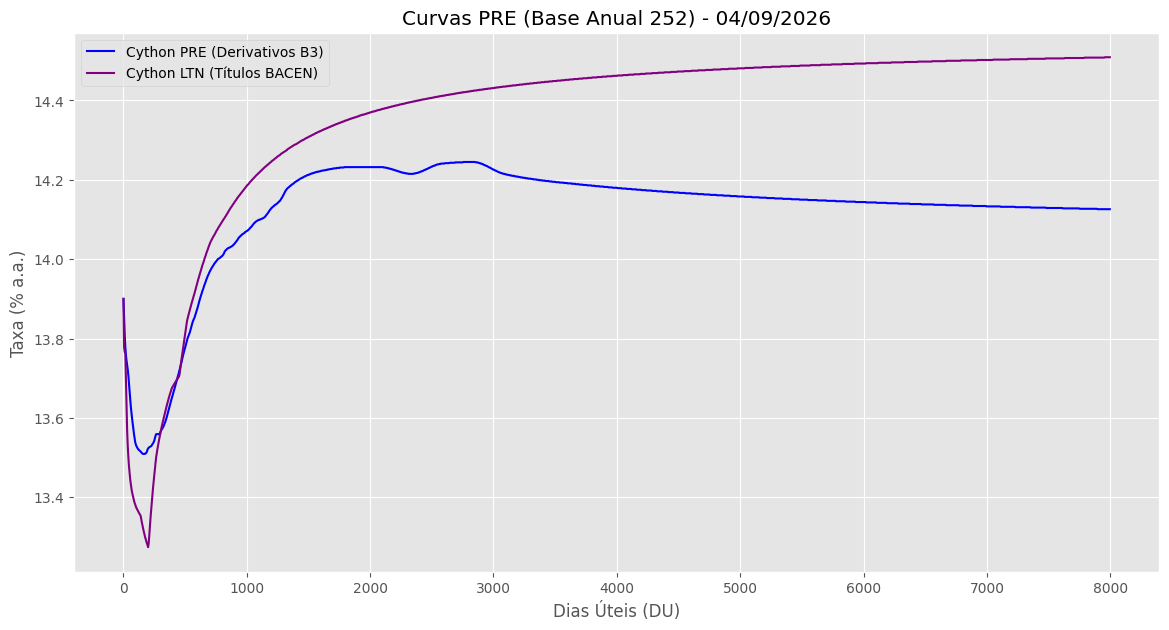

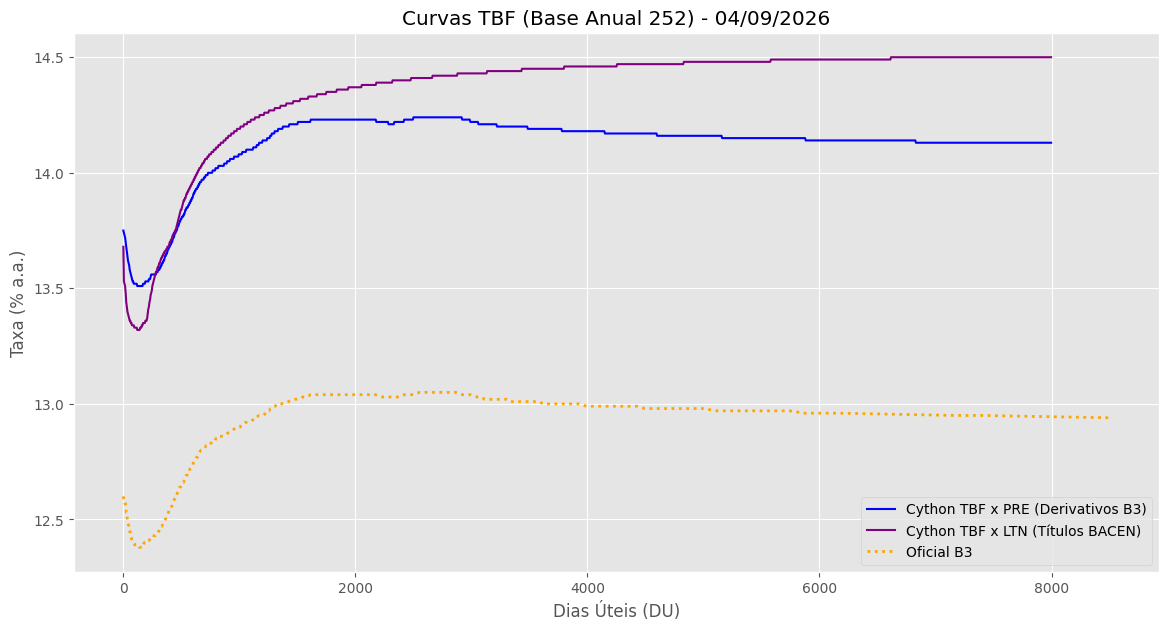

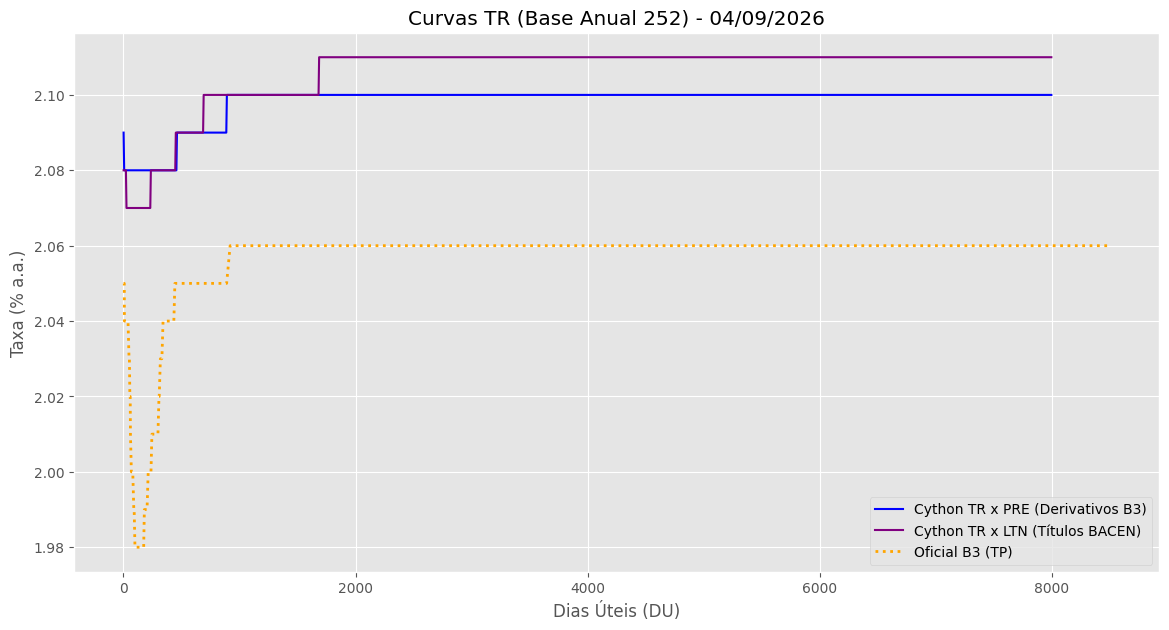

In [11]:
# 1. Curva PRE Base e Curvas TBF e TR via CurveManager (Seções 2.4 e 2.5 B3)
curve_pre = manager.get_curve('PRE', base_date)
curve_tbf_pre = manager.get_curve('TBF_PRE', base_date)
curve_tr_pre = manager.get_curve('TR_PRE', base_date)

# Curva baseada em títulos públicos (LTN)
curve_ltn = manager.get_curve('LTN', base_date)
curve_tbf_ltn = manager.get_curve('TBF_LTN', base_date)
curve_tr_ltn = manager.get_curve('TR_LTN', base_date)

# 2. Dados Oficiais B3
b3_tfp_path = scraper.download_taxas_referenciais(data=base_date, produto='TFP')
df_b3_tfp = pd.read_csv(b3_tfp_path, sep=';')
b3_tp_path = scraper.download_taxas_referenciais(data=base_date, produto='TP')
df_b3_tp = pd.read_csv(b3_tp_path, sep=';')

du_grid = np.arange(1, 8000, 5)

# ---- Gráfico TBF (TFP) ----
plt.figure(figsize=(14, 6))
plt.plot(du_grid, [curve_tbf_pre.get_rate(float(du)) * 100 for du in du_grid], label='Cython TBF x PRE (Seção 2.4 B3)', color='blue', linewidth=1.5)
plt.plot(du_grid, [curve_tbf_ltn.get_rate(float(du)) * 100 for du in du_grid], label='Cython TBF x LTN (Títulos BACEN)', color='purple', linestyle='--')
if df_b3_tfp is not None and not df_b3_tfp.empty:
    plt.plot(df_b3_tfp['day252'], df_b3_tfp['rate'], label='Oficial B3 (TFP)', color='orange', linestyle=':', linewidth=2.5)
plt.title(f'Curva TBF x PRE (TFP) - Comparativo B3 vs Cython - {base_date.strftime("%d/%m/%Y")}')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (% a.a.)')
plt.legend()
plt.show()

# ---- Gráfico TR (TP) ----
plt.figure(figsize=(14, 6))
plt.plot(du_grid, [curve_tr_pre.get_rate(float(du)) * 100 for du in du_grid], label='Cython TR x PRE (Res. CMN 5.124 / B3)', color='blue', linewidth=1.5)
plt.plot(du_grid, [curve_tr_ltn.get_rate(float(du)) * 100 for du in du_grid], label='Cython TR x LTN (Títulos BACEN)', color='purple', linestyle='--')
if df_b3_tp is not None and not df_b3_tp.empty:
    plt.plot(df_b3_tp['day252'], df_b3_tp['rate'], label='Oficial B3 (TP)', color='orange', linestyle=':', linewidth=2.5)
plt.title(f'Curva TR x PRE (TP) - Comparativo B3 vs Cython - {base_date.strftime("%d/%m/%Y")}')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (% a.a.)')
plt.legend()
plt.show()


## 5. Curvas de Inflação (DIC e DIM)

Arquivo de taxas referenciais (DIC - 20260904) já existe em: ../dados/b3\taxas_DIC_20260904.csv. Use force=True para baixar novamente.
Arquivo de taxas referenciais (DIM - 20260904) já existe em: ../dados/b3\taxas_DIM_20260904.csv. Use force=True para baixar novamente.


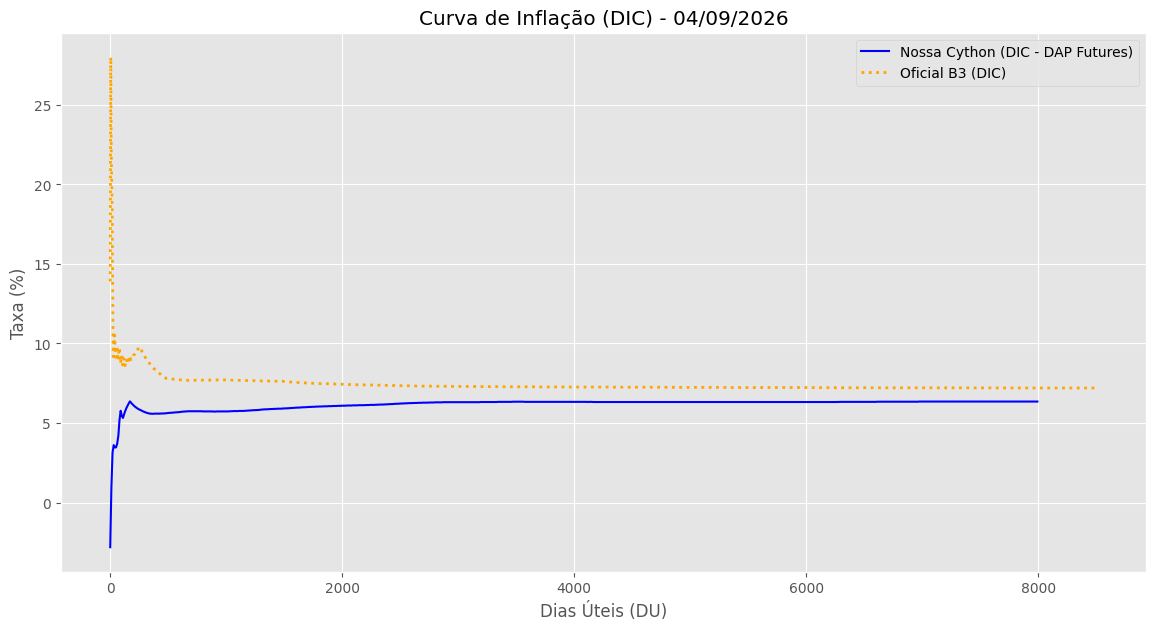

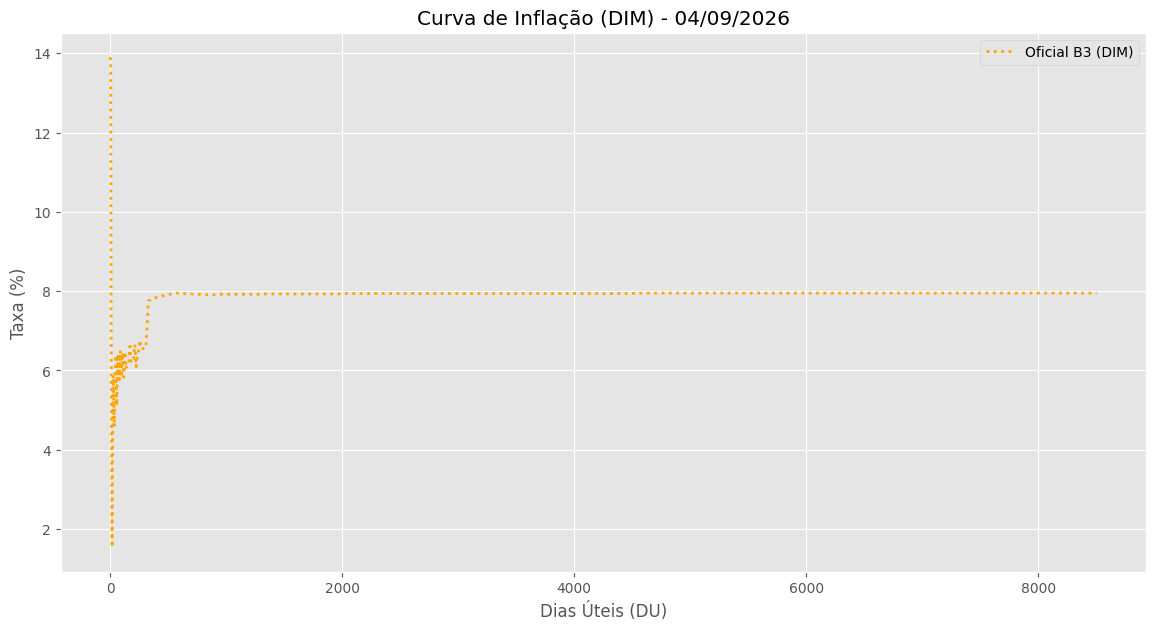

In [12]:
# Curvas de Inflação conforme Seções 3.1 (DIC), 3.2 (DPL) e 3.3 (DIM) do Manual de Curvas B3
# DIC e DIM representam as curvas de Cupom Sujo de IPCA e IGP-M
# DPL representa o Cupom Limpo de IPCA oriundo de contratos DAP e NTN-B
b3_dic_path = scraper.download_taxas_referenciais('DIC', base_date)
b3_dim_path = scraper.download_taxas_referenciais('DIM', base_date)
df_b3_dic = pd.read_csv(b3_dic_path, sep=';')
df_b3_dim = pd.read_csv(b3_dim_path, sep=';')

curve_dic = manager.get_curve('DIC', base_date)
curve_dpl = manager.get_curve('DPL', base_date)
curve_dim = manager.get_curve('DIM', base_date)

du_grid = np.arange(1, 8000, 10)

# ---- Gráfico DIC (Cupom Sujo IPCA) e DPL (Cupom Limpo IPCA) ----
plt.figure(figsize=(14, 6))
plt.plot(du_grid, [curve_dic.get_rate(float(du)) * 100 for du in du_grid], label='Cython DIC (Cupom Sujo IPCA - Seção 3.1 B3)', color='blue')
plt.plot(du_grid, [curve_dpl.get_rate(float(du)) * 100 for du in du_grid], label='Cython DPL (Cupom Limpo DAP - Seção 3.2 B3)', color='green', linestyle='--')
if df_b3_dic is not None and not df_b3_dic.empty:
    plt.plot(df_b3_dic['day252'], df_b3_dic['rate'], label='Oficial B3 (DIC)', color='orange', linewidth=2, linestyle=':')
plt.title(f'Curvas de Cupom de IPCA (DIC / DPL) - {base_date.strftime("%d/%m/%Y")}')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (% a.a.)')
plt.legend()
plt.show()

# ---- Gráfico DIM (Cupom Sujo IGP-M) ----
plt.figure(figsize=(14, 6))
plt.plot(du_grid, [curve_dim.get_rate(float(du)) * 100 for du in du_grid], label='Cython DIM (Cupom Sujo IGP-M - Seção 3.3 B3)', color='purple')
if df_b3_dim is not None and not df_b3_dim.empty:
    plt.plot(df_b3_dim['day252'], df_b3_dim['rate'], label='Oficial B3 (DIM)', color='orange', linewidth=2, linestyle=':')
plt.title(f'Curva de Cupom Sujo de IGP-M (DIM) - {base_date.strftime("%d/%m/%Y")}')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (% a.a.)')
plt.legend()
plt.show()


## 6. Curvas de Moedas (Forward PTX e Cupom Sujo DOL)

Arquivo de taxas referenciais (DOL - 20260904) já existe em: ../dados/b3\taxas_DOL_20260904.csv. Use force=True para baixar novamente.
Arquivo de taxas referenciais (PTX - 20260904) já existe em: ../dados/b3\taxas_PTX_20260904.csv. Use force=True para baixar novamente.


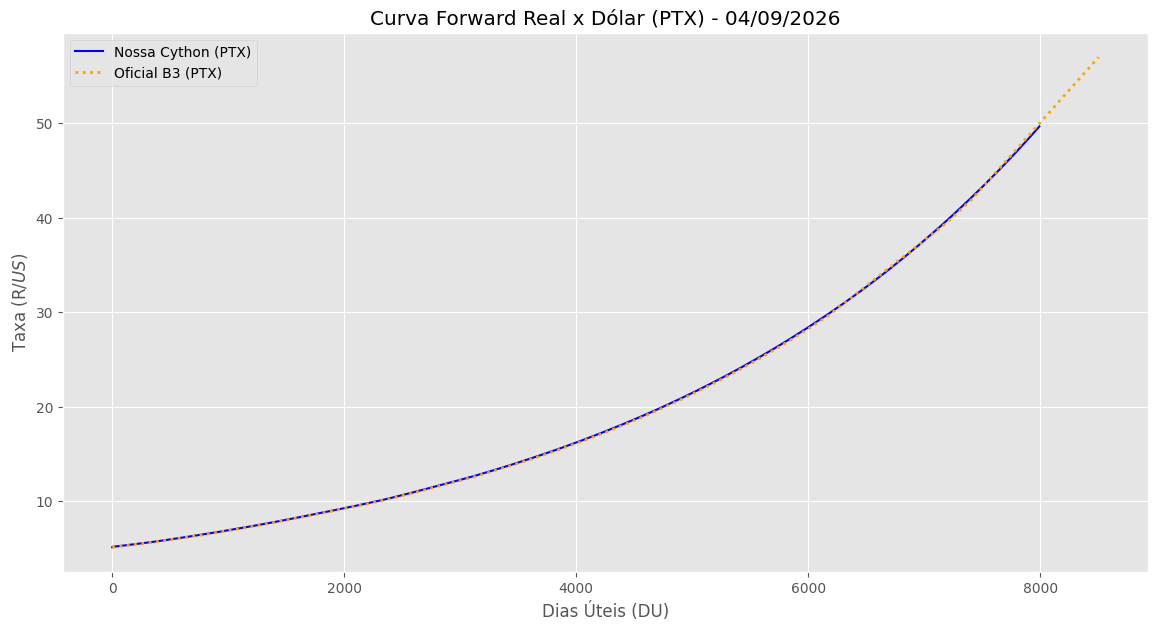

In [13]:
# Curva de Cupom Sujo DOL e Forward PTX

# Baixando oficiais
b3_dol_path = scraper.download_taxas_referenciais('DOL', base_date)
b3_ptx_path = scraper.download_taxas_referenciais('PTX', base_date)
df_b3_dol = pd.read_csv(b3_dol_path, sep=';')
df_b3_ptx = pd.read_csv(b3_ptx_path, sep=';')

# Extraindo contratos DDI (Cupom Sujo Dólar)
df_ddi = loader.get_curve_instruments(base_date, asst='DDI')
curve_dol = builder.build_from_config(df_ddi, 'DOL', base_date)

# Para a PTX, precisamos da Ptax e da Curva PRE
df_ptax = scraper.download_bcb_ptax(base_date)
# A Olinda API retorna uma lista de moedas. Filtramos pelo Dólar (simbolo 'USD')
ptax_usd = df_ptax[df_ptax['simbolo'] == 'USD']['cotacaoVenda'].iloc[0] if not df_ptax.empty else 5.50

# Usa a curve_pre_std já construída na seção 2
du_nodes = np.arange(1, 8000, 21, dtype=np.float64) # Um node por mes aprox
dc_nodes = np.array([builder.cal.bizdays(base_date, base_date + datetime.timedelta(days=int(d*1.45))) for d in du_nodes], dtype=np.float64)
# Como DC exato depende de dias corridos vs du, faremos uma aproximação para os nodes
dc_nodes = np.array([int(du * 360 / 252) for du in du_nodes], dtype=np.float64)

curve_ptx = builder.build_currency_forward_curve(curve_pre_std, curve_dol, ptax_usd, du_nodes, dc_nodes, 'PTX')

# Plot PTX
plt.figure()
rates_ptx = [curve_ptx.get_rate(float(du)) for du in du_grid]
plt.plot(du_grid, rates_ptx, label='Nossa Cython (PTX)', color='blue')
if df_b3_ptx is not None and not df_b3_ptx.empty:
    plt.plot(df_b3_ptx['day252'], df_b3_ptx['rate'], label='Oficial B3 (PTX)', color='orange', linewidth=2, linestyle=':')

plt.title(f'Curva Forward Real x Dólar (PTX) - {base_date.strftime("%d/%m/%Y")}')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (R$/US$)')
plt.legend()
plt.show()



## 7. Curvas Internacionais (SOFR e TIIE)

Baixando SOFR: https://markets.newyorkfed.org/api/rates/secured/sofr/search.json?startDate=2026-08-25&endDate=2026-09-04


d:\projects\bz_pricing\.venv\lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'markets.newyorkfed.org'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


Arquivo de taxas referenciais (LIB - 20260904) já existe em: ../dados/b3\taxas_LIB_20260904.csv. Use force=True para baixar novamente.


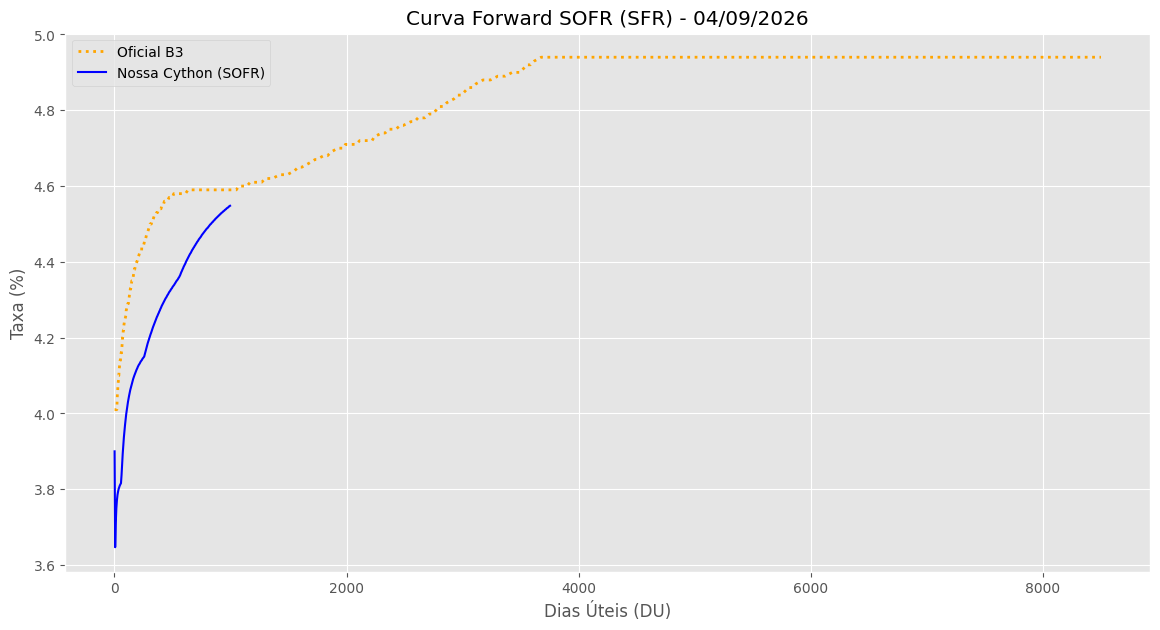

In [14]:
# Curvas Internacionais: SOFR (SFR - Futuros vs ZUS/LIB - Swaps Zero Cupom)
# Conforme Manual de Curvas B3:
# - Seção 2.8: Curva Forward de SOFR (SFR), construída a partir do Contrato Futuro de SOFR negociado na B3
# - Seção 2.11: Curva Zero Cupom de SOFR (ZUS), divulgada no arquivo 'LIB' baseada em fatores de desconto de Swaps SOFR
curve_sfr = manager.get_curve('SFR', base_date)

b3_sofr_path = scraper.download_taxas_referenciais(data=base_date, produto='LIB')
df_sofr_lib = pd.read_csv(b3_sofr_path, sep=';')

dc_grid = np.arange(1, 1000, 5)
rates_sfr = [curve_sfr.get_rate(float(dc)) * 100 for dc in dc_grid]

plt.figure(figsize=(14, 6))
plt.plot(dc_grid, rates_sfr, label='Cython SOFR Futuros (SFR - Seção 2.8 B3)', color='blue')
if df_sofr_lib is not None and not df_sofr_lib.empty:
    plt.plot(df_sofr_lib['day360'], df_sofr_lib['rate'], label='Oficial B3 Swaps SOFR (LIB/ZUS - Seção 2.11 B3)', color='orange', linestyle=':', linewidth=2)
plt.title(f'SOFR: Curva Forward de Futuros (SFR) vs Swaps Zero Cupom (LIB/ZUS) - {base_date.strftime("%d/%m/%Y")}')
plt.xlabel('Dias Corridos (DC)')
plt.ylabel('Taxa (% a.a.)')
plt.legend()
plt.show()
